In [8]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
from inspect_frame import read_labels

7481


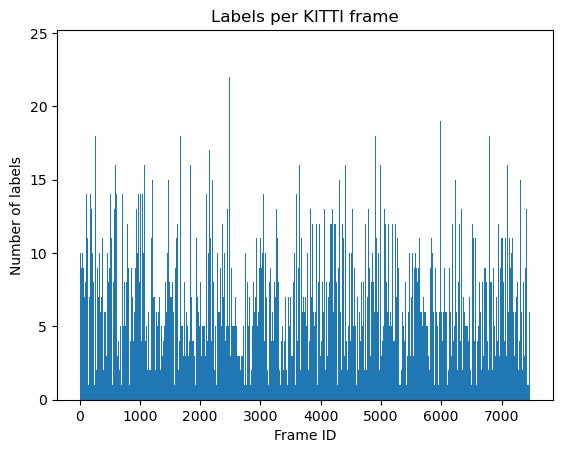

In [ ]:
# Make the local helper module importable regardless of the notebook working directory
sys.path.insert(0, '/home/riley/pc-occlusion-3/kitti')


DATA_ROOT = Path('/home/riley/OpenPCDet/data/kitti')
N = 50

def inspect(data_root=DATA_ROOT, frame_id='000000', show_plot=False):
    root = data_root / 'training'
    velo_files = sorted((root / 'velodyne').glob('*.bin'))
    print(len(velo_files))
    if not velo_files:
        raise FileNotFoundError(f'No Velodyne files found in {root / "velodyne"}')
    frame_ids = []
    label_counts = []
    for velo_path in velo_files[:N]:
        frame_id = velo_path.stem
        label_path = root / 'label_2' / f'{frame_id}.txt'
        if not label_path.is_file():
            raise FileNotFoundError(f'Missing label file for frame {frame_id}: {label_path}')

        labels = read_labels(label_path)
        # print(f'Frame {frame_id}: {len(labels)} labels')
        frame_ids.append(int(frame_id))
        label_counts.append(len(labels))
    plt.bar(frame_ids, label_counts, width=1.0)
    plt.xlabel("Frame ID")
    plt.ylabel("Number of labels")
    plt.title("Labels per KITTI frame")
    plt.show()

inspect()
